
# 🌀 Poseidon semplificato — Implementazione didattica in Python

Questa è una versione semplificata dell'algoritmo Poseidon, pensata per aiutarti a capire **ogni singolo passaggio** della funzione di hash, soprattutto per analisi **differenziali** e **lineari**.

🔍 Qui vedrai:
- Stato dopo ogni round
- S-box
- Matrice MDS
- Costanti di round
- Campo finito

Tutto è spiegato e visualizzabile. Puoi modificarlo a piacere per testare ipotesi o fare esperimenti di crittoanalisi.


In [171]:

# ⚙️ Parametri principali

# Campo finito piccolo (debug-friendly)
p = 251  # Primo grande abbastanza per test ma semplice (goldilocks)

# Numero di elementi nello stato (t=3)
t = 3

# Numero di round
full_rounds = 4
partial_rounds = 4
n_rounds = full_rounds + partial_rounds

# Esponente della S-box
alpha = 3


In [172]:

# 📏 Costanti di round (esempio: 8 round x 3 elementi = 24 costanti)
round_constants = [(i * 17 + 42) % p for i in range(n_rounds * t)] #al posto di 17,42 si possono usare altri numeri per generare costanti diverse

# 🧮 Matrice MDS fissa 3x3 (esempio didattico)
MDS = [
    [2, 3, 1],
    [1, 2, 3],
    [3, 1, 2]
]


In [173]:

# 🔢 Funzione S-box parte non lineare, poiché semplificato lo applichiamo a tutti gli elementi altrimenti lo dovremmo applicare soltanto su alcuni elementi 
def sbox(x):
    return pow(int(x), alpha, p)

# ♻️ Aggiunta costanti di round 
# state: è una lista o un vettore di numeri che rappresenta lo “stato” attuale dell’algoritmo.
# round_index: è il numero del round corrente (es. 0, 1, 2, …), cioè quale “passo” dell’algoritmo stiamo facendo.

def add_constants(state, round_index):
    return [(x + round_constants[round_index * t + i]) % p for i, x in enumerate(state)]

# 🔄 Moltiplicazione per matrice MDS
def mix(state):
    return [
        sum(state[j] * MDS[i][j] for j in range(t)) % p
        for i in range(t)
    ]


## 📦 INPUTS DELLA FUNZIONE

* `state`: è una lista con i valori attuali dell’algoritmo.
  Esempio: `state = [12, 34, 56]`
* `round_index`: è il numero del round corrente (0, 1, 2, ecc.)
* `round_constants`: è una lista più lunga, con TUTTE le costanti per TUTTI i round.
* `t`: è il numero di elementi nello stato (in questo caso 3).
* `p`: è il modulo del campo finito (es. 97, 257, o un numero molto più grande).

---

### 🔍 RIASSUNTO

```python
def add_constants(state, round_index):
    return [
        (x + round_constants[round_index * t + i]) % p
        for i, x in enumerate(state)
    ]
```

* `enumerate(state)` scorre lo stato dandoti **i = posizione**, **x = valore**
* `round_constants[round_index * t + i]` prende la costante giusta
* Si somma quella costante a `x` e si fa il modulo `p`
* Si restituisce la nuova lista (lo stato aggiornato)

In [174]:

# 🌀 Permutazione Poseidon
def poseidon_permutation(input_state):
    state = input_state[:]
    for r in range(n_rounds):
        print(f"🔁 Round {r}")
        
        # Add round constants
        state = add_constants(state, r)
        print("  ➕ After constants:", state)
        
        # Apply S-box
        if r < full_rounds // 2 or r >= n_rounds - full_rounds // 2:
            # Full round: tutte le S-box
            state = [sbox(x) for x in state]
        else:
            # Partial round: solo la prima S-box
            state = [sbox(state[0])] + state[1:]
        print("  🧮 After S-box:", state)
        
        # MDS mixing
        state = mix(state)
        print("  🔗 After MDS:", state)
        
    return state


In [175]:

# ▶️ Esempio di test

input_state = [1, 2, 5]  # Input di esempio

print("📥 Stato iniziale:", input_state)
output_state = poseidon_permutation(input_state)
print("\n📤 Stato finale:", output_state[0])

📥 Stato iniziale: [1, 2, 5]
🔁 Round 0
  ➕ After constants: [43, 61, 81]
  🧮 After S-box: [191, 77, 74]
  🔗 After MDS: [185, 65, 45]
🔁 Round 1
  ➕ After constants: [27, 175, 172]
  🧮 After S-box: [105, 23, 176]
  🔗 After MDS: [204, 177, 188]
🔁 Round 2
  ➕ After constants: [97, 87, 115]
  🧮 After S-box: [37, 87, 115]
  🔗 After MDS: [199, 54, 177]
🔁 Round 3
  ➕ After constants: [143, 15, 155]
  🧮 After S-box: [57, 15, 155]
  🔗 After MDS: [63, 50, 245]
🔁 Round 4
  ➕ After constants: [58, 62, 23]
  🧮 After S-box: [85, 62, 23]
  🔗 After MDS: [128, 27, 112]
🔁 Round 5
  ➕ After constants: [174, 90, 192]
  🧮 After S-box: [36, 90, 192]
  🔗 After MDS: [32, 39, 80]
🔁 Round 6
  ➕ After constants: [129, 153, 211]
  🧮 After S-box: [137, 58, 5]
  🔗 After MDS: [202, 17, 228]
🔁 Round 7
  ➕ After constants: [99, 182, 159]
  🧮 After S-box: [184, 50, 165]
  🔗 After MDS: [181, 26, 179]

📤 Stato finale: 181


In [176]:

# 🧪 Esperimento differenziale
# Input modificato con una piccola differenza

input_A = [1, 2, 3]
input_B = [1, 2, 4]  # Differenza su ultimo elemento

print("📥 Input A:", input_A)
out_A = poseidon_permutation(input_A)
print("\n📥 Input B:", input_B)
out_B = poseidon_permutation(input_B)

# Differenza in output
diff = [(a - b) % p for a, b in zip(out_A, out_B)]
print("\n🔬 Differenza in output:", diff)


📥 Input A: [1, 2, 3]
🔁 Round 0
  ➕ After constants: [43, 61, 79]
  🧮 After S-box: [191, 77, 75]
  🔗 After MDS: [186, 68, 47]
🔁 Round 1
  ➕ After constants: [28, 178, 174]
  🧮 After S-box: [115, 33, 36]
  🔗 After MDS: [114, 38, 199]
🔁 Round 2
  ➕ After constants: [7, 199, 126]
  🧮 After S-box: [92, 199, 126]
  🔗 After MDS: [154, 115, 225]
🔁 Round 3
  ➕ After constants: [98, 76, 203]
  🧮 After S-box: [193, 76, 203]
  🔗 After MDS: [64, 201, 57]
🔁 Round 4
  ➕ After constants: [59, 213, 86]
  🧮 After S-box: [61, 213, 86]
  🔗 After MDS: [94, 243, 66]
🔁 Round 5
  ➕ After constants: [140, 55, 146]
  🧮 After S-box: [68, 55, 146]
  🔗 After MDS: [196, 114, 49]
🔁 Round 6
  ➕ After constants: [42, 228, 180]
  🧮 After S-box: [43, 132, 15]
  🔗 After MDS: [246, 101, 40]
🔁 Round 7
  ➕ After constants: [143, 15, 222]
  🧮 After S-box: [57, 112, 209]
  🔗 After MDS: [157, 155, 199]

📥 Input B: [1, 2, 4]
🔁 Round 0
  ➕ After constants: [43, 61, 80]
  🧮 After S-box: [191, 77, 211]
  🔗 After MDS: [71, 225, 68]


## 🔍 Analisi Differenziale

In questa sezione esaminiamo come piccole differenze nell'input si propagano attraverso i round.


🔁 Round 0
  ➕ After constants: [43, 61, 79]
  🧮 After S-box: [191, 77, 75]
  🔗 After MDS: [186, 68, 47]
🔁 Round 1
  ➕ After constants: [28, 178, 174]
  🧮 After S-box: [115, 33, 36]
  🔗 After MDS: [114, 38, 199]
🔁 Round 2
  ➕ After constants: [7, 199, 126]
  🧮 After S-box: [92, 199, 126]
  🔗 After MDS: [154, 115, 225]
🔁 Round 3
  ➕ After constants: [98, 76, 203]
  🧮 After S-box: [193, 76, 203]
  🔗 After MDS: [64, 201, 57]
🔁 Round 4
  ➕ After constants: [59, 213, 86]
  🧮 After S-box: [61, 213, 86]
  🔗 After MDS: [94, 243, 66]
🔁 Round 5
  ➕ After constants: [140, 55, 146]
  🧮 After S-box: [68, 55, 146]
  🔗 After MDS: [196, 114, 49]
🔁 Round 6
  ➕ After constants: [42, 228, 180]
  🧮 After S-box: [43, 132, 15]
  🔗 After MDS: [246, 101, 40]
🔁 Round 7
  ➕ After constants: [143, 15, 222]
  🧮 After S-box: [57, 112, 209]
  🔗 After MDS: [157, 155, 199]
🔁 Round 0
  ➕ After constants: [43, 61, 80]
  🧮 After S-box: [191, 77, 211]
  🔗 After MDS: [71, 225, 68]
🔁 Round 1
  ➕ After constants: [164, 84, 1

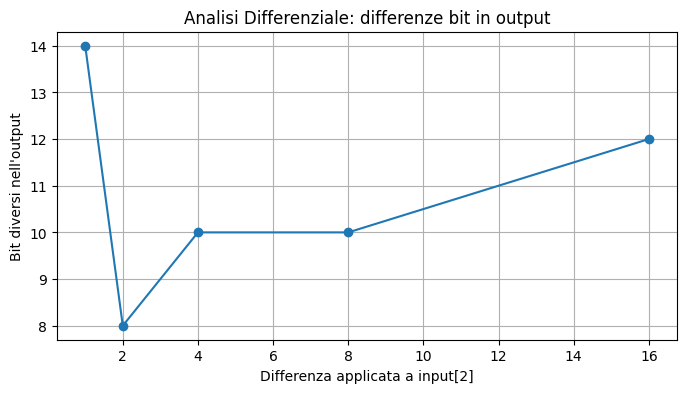

In [177]:

import matplotlib.pyplot as plt

def count_bit_differences(a, b):
    return sum(bin(x ^ y).count("1") for x, y in zip(a, b))

# Test con più input differenziali
base_input = [1, 2, 3]
differences = [1, 2, 4, 8, 16]
bit_diffs = []

for d in differences:
    mod_input = [1, 2, 3 + d]
    out_base = poseidon_permutation(base_input)
    out_mod = poseidon_permutation(mod_input)
    bit_diff = count_bit_differences(out_base, out_mod)
    bit_diffs.append(bit_diff)

plt.figure(figsize=(8, 4))
plt.plot(differences, bit_diffs, marker='o')
plt.title("Analisi Differenziale: differenze bit in output")
plt.xlabel("Differenza applicata a input[2]")
plt.ylabel("Bit diversi nell'output")
plt.grid(True)
plt.show()


indica cambiano x bit, quanti bit di differenza otteniamo nell output finale comparandoli


## 🧮 Analisi Lineare (semplificata)

Studiamo la relazione lineare tra input e output per osservare eventuali pattern lineari.


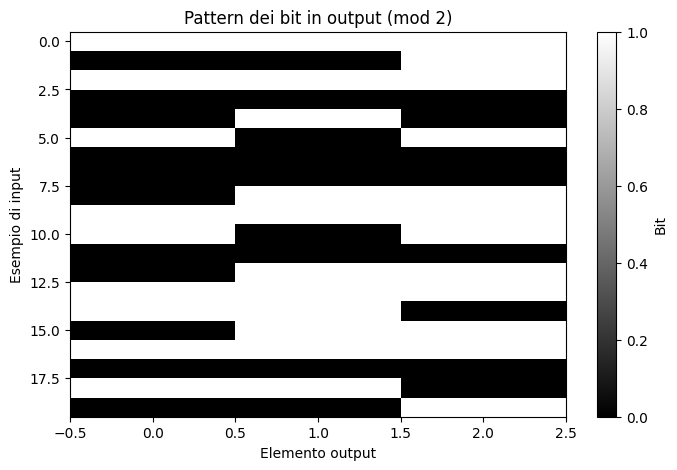

In [178]:

import numpy as np

# Usiamo una versione linearizzata per test (disattiviamo la S-box)
def poseidon_linearized(input_state):
    state = input_state[:]
    for r in range(n_rounds):
        state = add_constants(state, r)
        #state = [sbox(int(x)) for x in state]
        state = mix(state)
    return state

num_samples = 20
input_dim = 3  

# Genera input casuali e verifica output linearizzati
#inputs = [[i, i+1, i+2] for i in range(20)]
inputs = np.random.randint(0, p, size=(num_samples, input_dim))

outputs = [poseidon_linearized(inp) for inp in inputs]

# Costruzione matrice input-output
input_matrix = np.array(inputs)
output_matrix = np.array(outputs)

plt.figure(figsize=(8, 5))
plt.imshow(output_matrix % 2, cmap="gray", aspect="auto")
plt.title("Pattern dei bit in output (mod 2)")
plt.xlabel("Elemento output")
plt.ylabel("Esempio di input")
plt.colorbar(label="Bit")
plt.show()



## 📊 Analisi Statistica dell'Output

Qui analizziamo le statistiche di distribuzione e casualità degli output generati da Poseidon:

- **Distribuzione dei valori**
- **Entropia**
- **Frequenze dei bit**


🔁 Round 0
  ➕ After constants: [np.int64(205), np.int64(109), np.int64(138)]
  🧮 After S-box: [52, 120, 102]
  🔗 After MDS: [64, 96, 229]
🔁 Round 1
  ➕ After constants: [157, 206, 105]
  🧮 After S-box: [226, 239, 13]
  🔗 After MDS: [178, 241, 190]
🔁 Round 2
  ➕ After constants: [71, 151, 117]
  🧮 After S-box: [236, 151, 117]
  🔗 After MDS: [38, 136, 89]
🔁 Round 3
  ➕ After constants: [233, 97, 67]
  🧮 After S-box: [192, 97, 67]
  🔗 After MDS: [240, 85, 54]
🔁 Round 4
  ➕ After constants: [235, 97, 83]
  🧮 After S-box: [171, 97, 83]
  🔗 After MDS: [214, 112, 23]
🔁 Round 5
  ➕ After constants: [9, 175, 103]
  🧮 After S-box: [227, 175, 103]
  🔗 After MDS: [78, 133, 58]
🔁 Round 6
  ➕ After constants: [175, 247, 189]
  🧮 After S-box: [23, 187, 122]
  🔗 After MDS: [227, 10, 249]
🔁 Round 7
  ➕ After constants: [124, 175, 180]
  🧮 After S-box: [28, 23, 15]
  🔗 After MDS: [140, 119, 137]
🔁 Round 0
  ➕ After constants: [np.int64(131), np.int64(20), np.int64(37)]
  🧮 After S-box: [135, 219, 202]
 

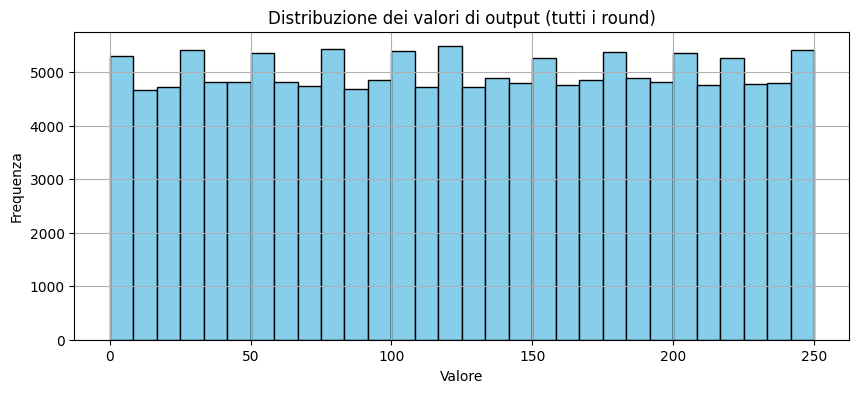

In [179]:

from collections import Counter
import math

# Genera molti output
num_samples = 50000
#inputs = [[i, i+1, i+2] for i in range(num_samples)]

inputs = np.random.randint(0, p, size=(num_samples, input_dim))
outputs = [poseidon_permutation(inp) for inp in inputs]

# Unisci tutti gli elementi output per analisi globale
flat_outputs = [x for out in outputs for x in out]

# Istogramma dei valori
plt.figure(figsize=(10, 4))
plt.hist(flat_outputs, bins=30, color='skyblue', edgecolor='black')
plt.title("Distribuzione dei valori di output (tutti i round)")
plt.xlabel("Valore")
plt.ylabel("Frequenza")
plt.grid(True)
plt.show()


In [180]:

# Calcolo entropia in bit
def entropy(values):
    c = Counter(values)
    total = sum(c.values())
    probs = [v / total for v in c.values()]
    return -sum(p * math.log2(p) for p in probs)

ent = entropy(flat_outputs)
print(f"🧠 Entropia dell'output: {ent:.4f} bit")


🧠 Entropia dell'output: 7.9704 bit


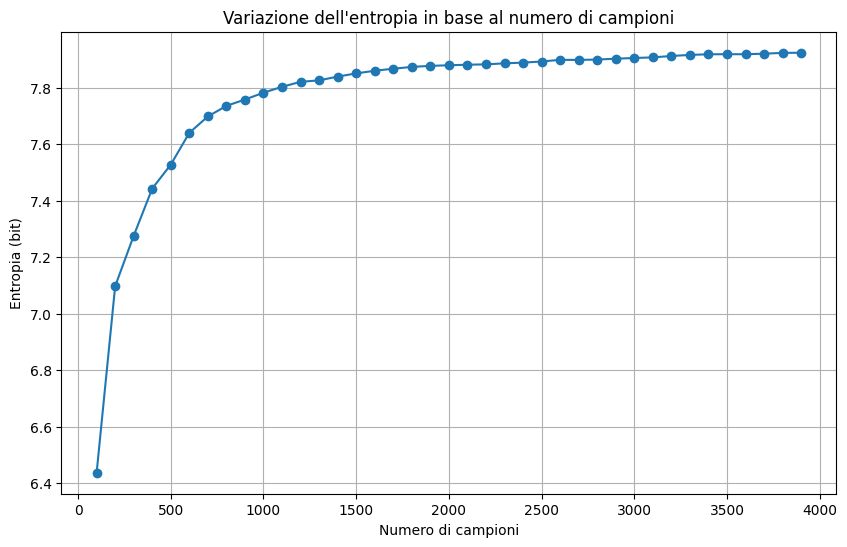

-------------
39


In [181]:
import math
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# La tua funzione entropia così com'è
def entropy(values):
    c = Counter(values)
    total = sum(c.values())
    probs = [v / total for v in c.values()]
    return -sum(p * math.log2(p) for p in probs)

# flat_outputs deve essere una lista o array di valori reali già definiti
num_sampless = list(range(100, 4000, 100))  # intervallo campioni da 100 a max, step 10
entropies = []

for size in num_sampless:
    sample = flat_outputs[:size]
    ent = entropy(sample)
    entropies.append(ent)

plt.figure(figsize=(10,6))
plt.plot(num_sampless, entropies, marker='o')
plt.title("Variazione dell'entropia in base al numero di campioni")
plt.xlabel("Numero di campioni")
plt.ylabel("Entropia (bit)")
plt.grid(True)
plt.show()

print("-------------")
print(len(entropies))

## 🔐 Cos’è l’entropia in crittografia?

L’**entropia** misura **l’imprevedibilità** o la **casualità** di una distribuzione.

### ✅ Se l’output del tuo cifratore ha **entropia massima**, significa:

* I valori sono **distribuiti uniformemente**
* Non ci sono **bias** o **pattern prevedibili**
* L’output è **simile a quello di un generatore casuale** (ottimo per la sicurezza)

### ❌ Se invece l’entropia è **bassa**, significa:

* Alcuni valori escono **più spesso** di altri
* Ci sono **correlazioni** o **ridondanze**
* L’output **non è sicuro** (un attaccante può sfruttare queste debolezze)


## 🔢 Cosa significa *quel valore unico* che ottieni?

Dipende da **quante possibili uscite** hai.
Supponiamo che i tuoi output siano interi tra 0 e 255 (es. byte). Allora:

* **Massima entropia possibile** = 8 bit (perché $\log_2(256) = 8$)
* Se ottieni:

  * **\~7.9 – 8.0** → Ottimo! Distribuzione quasi perfettamente casuale
  * **\~6 – 7.5** → Qualche bias, ma non troppo grave
  * **< 6** → Forte ridondanza → l’output **non è sicuro**

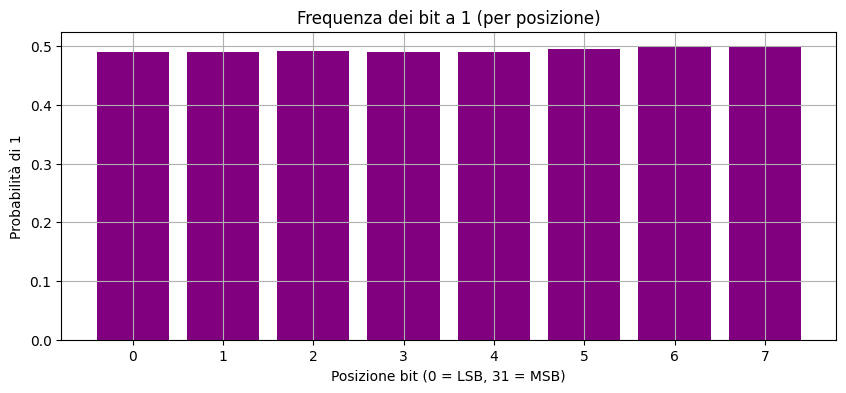

In [182]:

# Frequenze dei bit 0 e 1 su 32 bit per ogni valore
bit_counts = [0] * 8
for val in flat_outputs:
    bits = f"{val:08b}"
    for i, b in enumerate(bits):
        if b == "1":
            bit_counts[i] += 1

bit_probs = [c / len(flat_outputs) for c in bit_counts]

plt.figure(figsize=(10, 4))
plt.bar(range(8), bit_probs, color='purple')
plt.title("Frequenza dei bit a 1 (per posizione)")
plt.xlabel("Posizione bit (0 = LSB, 31 = MSB)")
plt.ylabel("Probabilità di 1")
plt.grid(True)
plt.show()


## 📘 Obiettivo

Capire **come funziona Poseidon** (una funzione hash per blockchain) e fare **attacchi crittoanalitici** (differenziali, lineari) e **analisi statistiche**.”

Ma il Poseidon vero è **troppo complicato**, quindi ti ho fatto una **versione semplificata** per imparare **passo per passo**, con tutto che puoi vedere e toccare col codice.

## 🧠 Parte 1: Poseidon semplificato

### 🔢 Il campo finito

* Tutti i numeri usati stanno dentro un insieme chiamato **campo finito**: si prende un numero molto grande `p = 2³¹ − 1`, e tutto quello che facciamo (somme, potenze) è **modulo p**.

---

### 📦 Lo stato

* Poseidon lavora su un **vettore di 3 numeri** (`t = 3`), come `[x, y, z]`
* Ogni **round** trasforma questo stato passo dopo passo.

---

### 🔁 I Round

Per ogni round (ne abbiamo 8), facciamo 3 cose:

1. **Aggiunta costanti** → sommiamo numeri speciali per confondere il tutto.
2. **S-box** → trasformiamo uno o tutti i numeri facendo `x⁵ mod p` (non lineare).
3. **MDS** → mischiamo i numeri moltiplicandoli per una matrice 3x3.

---

### 🔍 Tracciamento passo-passo

Nel codice, dopo **ogni round**, stampiamo:

* Stato dopo aggiunta costanti
* Stato dopo la S-box
* Stato dopo la matrice MDS

---

## 🧪 Parte 2: Analisi Differenziale

* Preso un input `[1, 2, 3]`
* Fatto una copia con un piccolo cambiamento: `[1, 2, 3 + d]`
* Ho guardato come cambia l’**output finale**
* Ho contato **quanti bit cambiano** (differenza bitwise) tra i due output

📊 Poi ho fatto un **grafico**:

* X = la differenza d applicata
* Y = quanti bit cambiano

### ✨ Obiettivo:

Capire se Poseidon è sensibile alle piccole differenze (spoiler: sì, cambia tutto anche se modifichi poco).

---

## 🧮 Parte 3: Analisi Lineare

In questa parte ho **tolto la S-box** (quella che fa `x⁵`) per vedere se Poseidon **senza non linearità** è **troppo prevedibile** (cioè troppo “lineare”).

1. Ho creato tanti input `[0,1,2], [1,2,3], …`
2. Ho eseguito Poseidon **senza la S-box**
3. Ho messo tutti gli output in una tabella
4. Ho disegnato un **grafico in scala di grigi**: i bit a 1 sono chiari, a 0 sono scuri

### ✨ Obiettivo:

Vedere se c’è qualche **pattern visivo** nei bit → e sì, senza la S-box si vedono cose regolari (male per la sicurezza!).

---

## 📊 Parte 4: Analisi Statistica

Ora che sappiamo che Poseidon mescola bene, vogliamo **verificare se gli output sono davvero “casuali”**.

### 🎯 Cosa ho fatto:

1. Ho preso **200 input** diversi
2. Ho raccolto **tutti gli output** (3 numeri × 200 input = 600 numeri)

Poi ho fatto:

---

### 1. 📈 Istogramma

Un **grafico a barre** con la distribuzione dei numeri:

* Così vediamo **quali valori compaiono più spesso**.

---

### 2. 🧠 Entropia

Ho calcolato **quanto è casuale** l’output:

* Se tutti i valori appaiono uguali → entropia alta (bene!)
* Se solo pochi si ripetono → entropia bassa (male!)

---

### 3. 🧬 Bit per bit

Ho preso ogni numero (32 bit) e ho contato **quante volte ogni bit è 1**:

* Bit 0 → quante volte è 1
* Bit 1 → quante volte è 1
* …
* Bit 31 → quante volte è 1

📊 Poi ho fatto un **grafico a barre**.

### ✨ Obiettivo:

Vedere se ogni bit è acceso/spento **circa metà delle volte** → segno che la funzione è bilanciata (cioè non ha bias).


Perfetto, Alessandro! Ti faccio una lista super chiara, ordinata e precisa di **tutte le differenze** tra la versione **semplificata** che ti ho dato e la versione **vera e completa** di Poseidon.

---

# Differenze tra **Poseidon Semplificato** e **Poseidon Normale**

| Aspetto                        | Poseidon Semplificato (tuo notebook)                      | Poseidon Normale (vero algoritmo)                                                                                    |
| ------------------------------ | --------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------- |
| **Campo finito**               | Usato un primo grande $p = 2^{31}-1$ (numero più piccolo) | Campo finito di ordine molto grande (tipicamente $p$ 254 bit o più) per sicurezza                                    |
| **Dimensione dello stato $t$** | Stato di 3 elementi (vettore $[x,y,z]$)                   | Stato con dimensioni maggiori, es. $t=6,8,12$ (dipende dalla configurazione)                                         |
| **Numero di round**            | Fisso a 8 round                                           | Variabile, tipicamente 63 o più, calcolati per sicurezza crittografica                                               |
| **Costanti di round**          | Costanti fisse e semplici (esempio: $c = [1,2,3]$)        | Costanti derivate da generatori sicuri, spesso generate con funzioni crittografiche                                  |
| **S-Box**                      | Funzione semplice $x^5 \mod p$                            | S-Box scelta attentamente (es. $x^5$ o $x^3$), con ottimizzazioni specifiche                                         |
| **Applicazione S-Box**         | S-Box applicata a **tutti** gli elementi ogni round       | S-Box applicata solo a uno o più elementi in round specifici (full rounds e partial rounds)                          |
| **Matrice MDS**                | Matrice 3x3 statica scelta arbitrariamente                | Matrice MDS ottimizzata, generata per avere proprietà crittografiche precise (inversione, diffusione massima)        |
| **Struttura round**            | Round uniforme (tutti uguali)                             | Mix di **full rounds** (S-box su tutti elementi) e **partial rounds** (S-box su uno solo) per efficienza e sicurezza |
| **Funzioni ausiliarie**        | Nessuna, codice base molto semplice                       | Numerose ottimizzazioni, come compressione, ottimizzazione per hardware, trasformazioni modulari                     |
| **Campo di applicazione**      | Solo esempio didattico                                    | Algoritmo usato in blockchain, zk-SNARKs, proof systems, con alta sicurezza                                          |
| **Efficienza**                 | Molto lenta, codice non ottimizzato                       | Ottimizzata in C/Rust, con implementazioni hardware/software veloci                                                  |


[![Poseidon Hash Function - SotaZK Labs docs](https://images.openai.com/thumbnails/54b88c8e9cde8207e1e85494077e537b.png)](https://docs.sotazk.org/terms/poseidon_hash_function/)

Spiegazione dettagliata e chiara riguardo alla **distribuzione dei valori** nella funzione hash Poseidon, confrontando la versione semplificata con la versione completa e ottimizzata utilizzata in contesti reali.

---

## 🧮 Distribuzione dei Valori: Versione Semplificata vs. Versione Completa

### 1. **Campo Finito e Dimensione dello Stato**

* **Versione Semplificata**: Utilizza un campo finito di piccole dimensioni, ad esempio $p = 2^{31} - 1$, e uno stato di dimensione $t = 3$. Questo approccio semplificato è utile per scopi didattici, ma non offre la robustezza necessaria per applicazioni crittografiche reali.

* **Versione Completa**: Impiega campi finiti di dimensioni molto più grandi, come $p \approx 2^{255}$, e stati di dimensioni maggiori, ad esempio $t = 6$ o $t = 8$. Queste scelte garantiscono una maggiore sicurezza e resistenza agli attacchi crittografici.

### 2. **Numero di Round e Struttura della Permutazione**

* **Versione Semplificata**: Implementa un numero ridotto di round (ad esempio, 8), con una struttura di permutazione uniforme. Questo rende l'algoritmo più facile da comprendere, ma meno sicuro.

* **Versione Completa**: Adotta un numero significativamente maggiore di round (ad esempio, 63 o più), con una struttura di permutazione che include sia round completi che parziali. Questa complessità aumenta la sicurezza dell'algoritmo.

### 3. **Funzione S-Box e Operazioni Non Lineari**

* **Versione Semplificata**: Utilizza una funzione S-Box semplice, come $x^5 \mod p$, per introdurre non linearità. Sebbene efficace per scopi educativi, questa scelta potrebbe non essere ottimale per applicazioni crittografiche avanzate.

* **Versione Completa**: Impiega funzioni S-Box più sofisticate e ottimizzate, come $x^7 \mod p$, che sono state progettate per offrire una maggiore resistenza agli attacchi lineari e differenziali.

### 4. **Matrice MDS e Diffusione**

* **Versione Semplificata**: Utilizza una matrice MDS (Maximum Distance Separable) di dimensioni 3x3, scelta arbitrariamente. Questo approccio semplificato potrebbe non garantire una diffusione ottimale dei dati.

* **Versione Completa**: Adotta matrici MDS ottimizzate, progettate per massimizzare la diffusione e ridurre la possibilità di attacchi crittografici.

### 5. **Analisi Statistica e Comportamento dell'Output**

* **Versione Semplificata**: La distribuzione dei valori di output può presentare anomalie o schemi riconoscibili, indicando una possibile mancanza di casualità. Ad esempio, la frequenza dei bit a 1 potrebbe non essere uniforme, suggerendo una bassa entropia.

* **Versione Completa**: La distribuzione dei valori di output è progettata per essere uniforme e casuale, con una frequenza dei bit a 1 distribuita uniformemente su tutte le posizioni. Questo comportamento è indicativo di un'alta entropia e di una buona qualità statistica dell'algoritmo.

